# Atividade Prática: Manipulação e Decisões de Visualização de Dados das IFES

**Dupla:** Nathan Mateus de Lima e Vítor Oliveira Amorim  
**Professora:** Carolina Ribeiro Xavier  
**Disciplina:** Tecnologias para Data Science  

In [101]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

sns.set_theme(style='whitegrid')

## Etapa 1 - Carregar, Preparar e Explorar os Dados

In [6]:
df = pd.read_csv("dados_investimento_e_vagas_ifes.csv")
df.head()

,ano,investimento_total_ifes_bilhoes_brl,investimento_assistencia_estudantil_bilhoes_brl,num_vagas_estudantes,num_vagas_docente,num_vagas_tae,num_terceirizados
0,1996,32.1,0.02,342100,26800,43100,8200
1,1997,31.8,0.02,351400,27100,42800,8600
2,1998,30.5,0.03,362900,27400,42100,9100
3,1999,29.8,0.03,375200,27600,41500,9800
4,2000,31.2,0.04,391800,28100,41900,10400


### Evolução Temporal e Ajuste de Escalas

**Agrupa os dados por anos**

In [7]:
df_agrupado = (
    df.groupby('ano')
    .agg(
        {
            'investimento_total_ifes_bilhoes_brl': 'sum',
            'num_vagas_estudantes': 'sum',
        }
    )
    .reset_index()
)

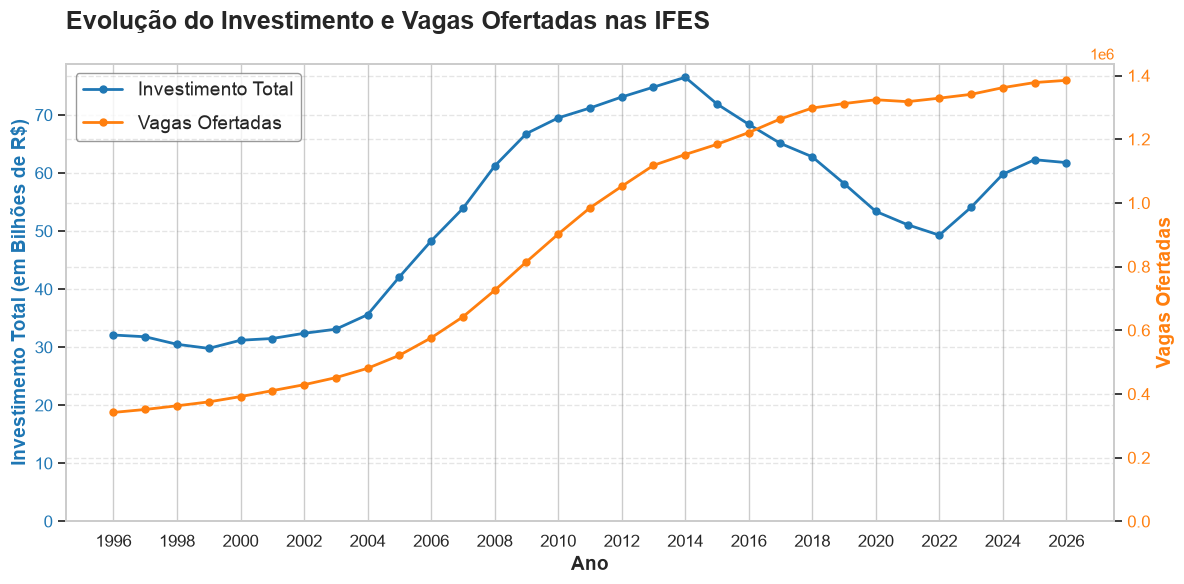

In [225]:
fig, ax1 = plt.subplots(figsize=(12, 6))

color = 'tab:blue'
ax1.set_xlabel('Ano', fontsize=14, fontweight='bold')

ax1.set_ylabel(
    'Investimento Total (em Bilhões de R$)',
    color=color,
    fontsize=14,
    fontweight='bold',
)
line1 = ax1.plot(
    df_agrupado['ano'],
    df_agrupado['investimento_total_ifes_bilhoes_brl'],
    color=color,
    linewidth=2,
    label='Investimento Total',
    marker='o',
    markersize=5,
)
ax1.set_xticks(df_agrupado['ano'])
ax1.xaxis.set_major_locator(ticker.MultipleLocator(2)) # xlabel de 2 em 2 anos
ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelcolor=color, labelsize=12)

ax2 = ax1.twinx()
color = 'tab:orange'
ax2.set_ylabel(
    'Vagas Ofertadas',
    color=color,
    fontsize=14,
    fontweight='bold',
)
line2 = ax2.plot(
    df_agrupado['ano'],
    df_agrupado['num_vagas_estudantes'],
    color=color,
    linewidth=2,
    linestyle='-',
    label='Vagas Ofertadas',
    marker='o',
    markersize=5,
)
ax2.tick_params(axis='y', labelcolor=color, labelsize=12)

lines = line1 + line2
labels = [l.get_label() for l in lines]
ax1.legend(
    lines, 
    labels, 
    loc='upper left', 
    frameon=True, 
    fontsize=14,
    edgecolor='gray',
    labelspacing=0.8,
)

# Deixa as linhas horizontais de referencia mais discretas
ax1.yaxis.grid(True, linestyle='--', alpha=0.2, color='gray')
ax2.yaxis.grid(True, linestyle='--', alpha=0.2, color='gray')
ax1.set_axisbelow(True)

# Força com que os exios y comecem em 0
ax1.set_ylim(bottom=0)
ax2.set_ylim(bottom=0)

plt.title(
    'Evolução do Investimento e Vagas Ofertadas nas IFES',
    fontsize=18,
    pad=25,
    fontweight='bold',
    loc='left'
)

fig.tight_layout()
plt.show()

A análise do gráfico de linha com eixo duplo, percebe-se que o **Investimento Total** e **Número de Vagas para Estudantes** cresce de forma conjunta até por volta do ano de 2004. No período de 2005 até 2014 o Investimento Total apresentou maior crescimento que o Número de Vagas, embora ambos tenham apresentado crescimento considerável. 

De 2015 a 2022, o Investimento Total apresentou uma forte tendência de queda, voltando a crescer somente após 2022. Entretanto, esse padrão de queda no Investimento Total não foi percebido no Número de Vagas para Estudantes, o qual, apesar de apresentar um crescimento menos acentuado do que seus anos anteriores, continuou crescendo mesmo com menos investimentos.

Para esta análise, foi utilizado um gráfico de linha com eixo duplo, devido a discrepância nas ordens de grandeza das variáveis "Investimento Total" e "Número de Vagas". O eixo duplo permite que os dois valores sejam analisados, sem que os valores de Número de Vagas de Estudantes que estão na casa dos milhares, sejam "achatados" na representação, quando comparado com Investimento Total cujos os valores estão na casa dos bilhões.

## Etapa 2 - Análise de Proporção de Força de Trabalho (Docentes vs. TAEs)

In [33]:
df['prop_estudante_docente'] = df['num_vagas_estudantes'] / df['num_vagas_docente']
df['prop_estudante_tae'] = df['num_vagas_estudantes'] / df['num_vagas_tae']

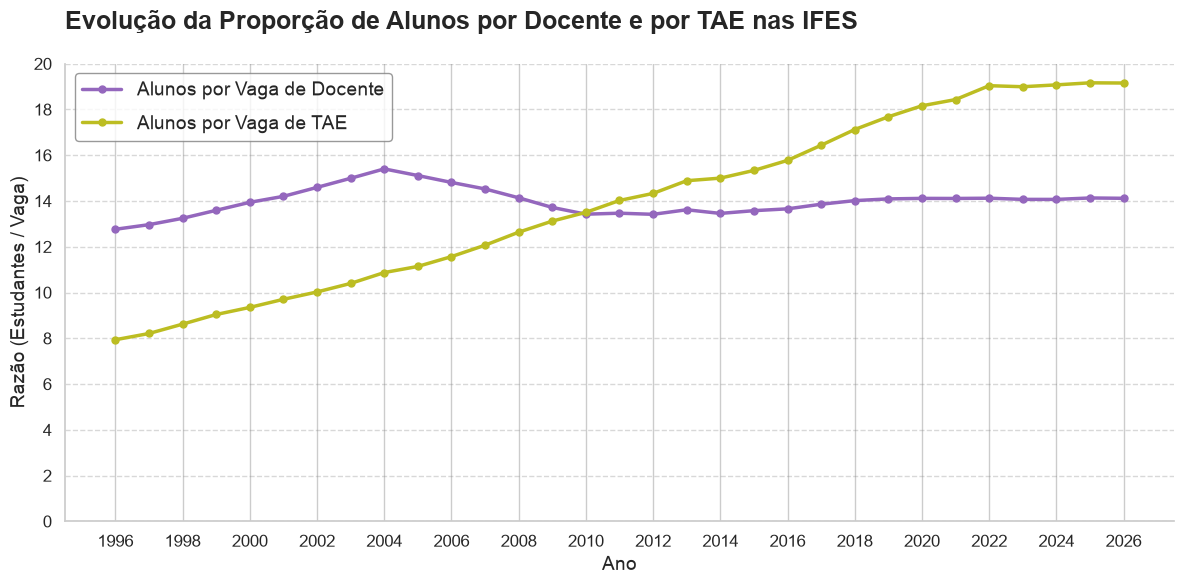

In [223]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df['ano'],
    df['prop_estudante_docente'],
    label='Alunos por Vaga de Docente',
    linewidth=2.5,
    color='tab:purple',
    marker='o',
    markersize=5,
)

ax.plot(
    df['ano'],
    df['prop_estudante_tae'],
    label='Alunos por Vaga de TAE',
    linewidth=2.5,
    color='tab:olive',
    marker='o',
    markersize=5,
)

plt.title(
    'Evolução da Proporção de Alunos por Docente e por TAE nas IFES',
    fontsize=18,
    pad=25,
    fontweight='bold',
    loc='left'
)

plt.xlabel('Ano', fontsize=14)
plt.ylabel('Razão (Estudantes / Vaga)', fontsize=14)

anos_xticks = range(df['ano'].min(), df['ano'].max() + 1, 2)
prop_yticks = range(0, int(max([df['prop_estudante_docente'].max(), df['prop_estudante_tae'].max()])) + 2, 2)
plt.xticks(anos_xticks, fontsize=12)
plt.yticks(prop_yticks, fontsize=12)

# Deixa as linhas horizontais de referencia mais discretas
ax.yaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
ax.set_axisbelow(True)

# Remove as bordas desnecessarias do grafico
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend(
    loc='upper left',
    fontsize=14,
    frameon=True,
    edgecolor='gray',
    labelspacing=0.8,
)

plt.tight_layout()
plt.show()

O gráfico deixa claro que a quantidade de alunos (número de vagas para estudantes) por vaga docente apresentou um comportamento estável, enquanto a linha de alunos por vaga TAE apresentou um crescimento contínuo (mais que dobrou entre 1996 até 2026), demonstrando um déficit crescente de técnicos administrativos nas IFES. Esse comportamento deixa claro que as autoridades públicas devem investigar questões relacionadas à carga de trabalho imposta aos TAE's, que possívelmente estão tendo que cobrir o trabalho que deveria estar sendo feito por outro colega.

A escolha desse gráfico se deve à smilaridade entre as escalas de valores. O gráfico com múltiplas linhas permite uma comparação direta entre as variáveis e permite ver sua atualização ao passar dos anos. Além disso, esse tipo de gráfico é ideal para a visualização de dados em escala temporal. As cores escolhidas se devem ao fato de que neste gráfico estamos tratando variáveis categóricas, e optamos por usar cores diferentes das do gráfico anterior, para evitar que terceiros interpretem que eles tem alguma relação direta.

Garantimos que ambos os eixos y comecem em 0 para não enganar o leitor a respeito da escala dos dados.

## Etapa 3 - Correlação entre Fatores e Desempenho Orçamentário

In [154]:
def categorizar_periodo(ano):
    if ano <= 2002:
        return 'FHC'
    elif 2003 <= ano <= 2010:
        return 'Lula'
    elif 2011 <= ano <= 2016:
        return 'Dilma'
    elif 2017 <= ano <= 2018:
        return 'Temer'
    elif 2019 <= ano <= 2022:
        return 'Bolsonaro'
    else: 
        return 'Lula'

df['governo'] = df['ano'].apply(categorizar_periodo)

In [155]:
resumo_agg = df.groupby('governo').agg({
    'investimento_assistencia_estudantil_bilhoes_brl': ['mean', 'median', 'sum'],
    'num_vagas_estudantes': ['mean', 'median', 'min', 'max'], # extrair soma daqui seria contar a mesma vaga 2x
})
print(resumo_agg)

          investimento_assistencia_estudantil_bilhoes_brl               \
                                                     mean median   sum   
governo                                                                  
Bolsonaro                                        1.100000  1.120  4.40   
Dilma                                            1.190000  1.245  7.14   
FHC                                              0.032857  0.030  0.23   
Lula                                             0.605000  0.515  7.26   
Temer                                            1.235000  1.235  2.47   

          num_vagas_estudantes                               
                          mean     median      min      max  
governo                                                      
Bolsonaro         1.320750e+06  1321000.0  1312000  1329000  
Dilma             1.118583e+06  1135000.0   984500  1221000  
FHC               3.804286e+05   375200.0   342100   429100  
Lula              8.816667e+05   77

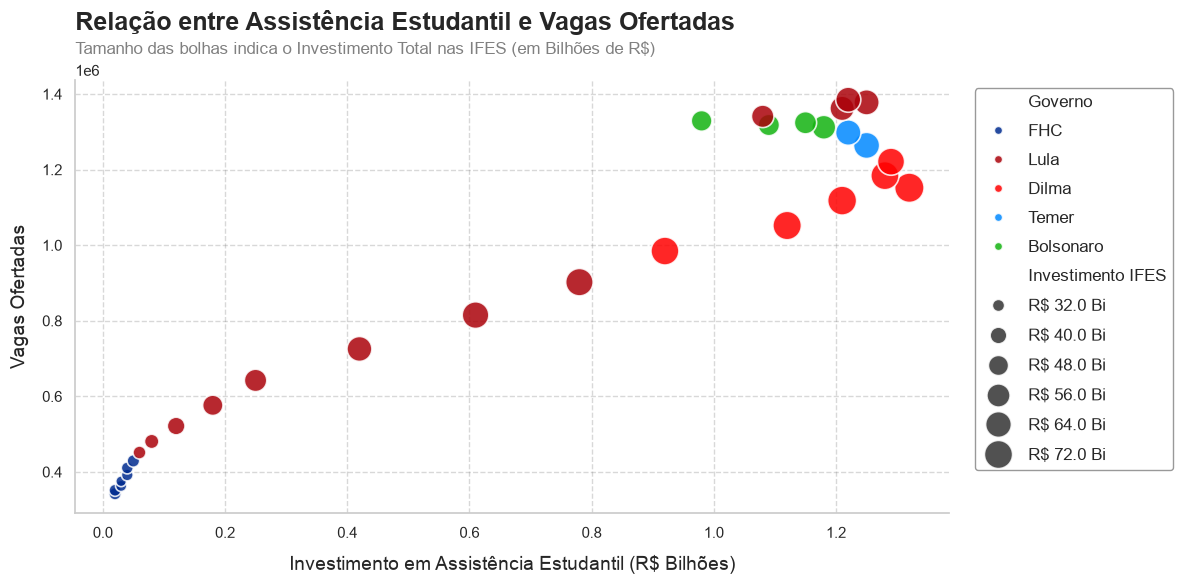

In [ ]:
fig, ax = plt.subplots(figsize=(12, 6))

paleta_governos = {
    'Lula': '#ab020a',
    'Dilma': '#ff0000',
    'FHC': '#002b8f',
    'Temer': '#0088ff',
    'Bolsonaro': '#13b310'
}

scatter = sns.scatterplot(
    data=df,
    x='investimento_assistencia_estudantil_bilhoes_brl',
    y='num_vagas_estudantes',
    size='investimento_total_ifes_bilhoes_brl',
    hue='governo',
    palette=paleta_governos,
    sizes=(60, 450),
    alpha=0.85,
    edgecolor='white',
    linewidth=1.2,
    ax=ax
)

# Deixa as linhas horizontais de referencia mais discretas
ax.xaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
ax.yaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
ax.set_axisbelow(True)

# Remove as bordas desnecessarias do grafico
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax1.tick_params(axis='x', labelsize=12)
ax1.tick_params(axis='y', labelsize=12)

plt.title(
    'Relação entre Assistência Estudantil e Vagas Ofertadas',
    fontsize=18,
    fontweight='bold',
    loc='left',
    pad=36
)
# Subtítulo
ax.text(
    x=0, y=1.06,
    s='Tamanho das bolhas indica o Investimento Total nas IFES (em Bilhões de R$)',
    transform=ax.transAxes,
    fontsize=12,
    color='gray',
)

plt.xlabel('Investimento em Assistência Estudantil (R$ Bilhões)', fontsize=14, labelpad=10)
plt.ylabel('Vagas Ofertadas', fontsize=14, labelpad=10)

# Construção da legenda
handles, labels = ax.get_legend_handles_labels()
labels_df_substituicao = {
    'governo': 'Governo',
    'investimento_total_ifes_bilhoes_brl': 'Investimento IFES'
}

labels_formatados = list()
for label in labels:
    if label in labels_df_substituicao:
        labels_formatados.append(labels_df_substituicao[label])
    else:
        try: # para os valores de investimento
            valor = float(label)
            labels_formatados.append(f'R$ {valor:.1f} Bi')
        except: # para os governos
            labels_formatados.append(label) 

ax.legend(
    handles=handles,
    labels=labels_formatados,
    bbox_to_anchor=(1.02, 1),
    loc='upper left',
    frameon=True,
    edgecolor='gray',
    labelspacing=0.8,
    fontsize=12,
)

plt.tight_layout()
plt.show()

A análise do gráfico de dispersão com tamanho de ponto proporcional nos revela que o período de 1996-2002 (governo FHC) teve os menores valores tanto de investimento total, como de número de vagas ofertadas à estudantes e investimento em assistência estudantil. Apesar disso, o investimento em assistência escolar apresentou um leve crescimento. O número de vagas ofertadas teve um crescimento mais expressivo, provavelmente em razão do fato de que muitas IFES estavam sendo criadas no país.

O período de 2003-2010 (governo Lula) apresentou o maior crecimento nos investimentos, tanto nas IFES quanto em assistência estudantil. No mesmo sentido, o período de 2011-2016 (governo Dilma) ainda apresentou um aumento nos investimentos, mas menos acentuado que no período anterior. Quanto ao número de vagas, o padrão também foi de crescimento. Já o período de 2017-2018 (governo Temer) apresentou leve queda nos investimentos, mas não muito considerável, frente ao crescimento dos anos anteriores. Apesar disso, o número de vagas ofertadas aos estudantes ainda foi crescente.

Por outro lado, no período de 2019-2022 (governo Bolsonaro) ambos os investimentos apresentaram a maior queda dentre os períodos analisados. Contudo, o número de vagas ofertadas não sofreu grandes alterações.

Por fim, no período de 2023-2026 (governo Lula) os investimentos nas IFES e em assistência estudantil voltaram a crescer, retomando os patamares do período de 2017-2018. Quanto ao número de vagas ofertadas, o crescimento não foi tão significativo, especialmente se comparado com os períodos anteriores.

A escolha do gráfico de *scatterplot* foi feita devido à sua capacidade de agregar as três informações necessárias ao mesmo tempo. Com isso, ele permite uma análise associativa sem a necessidade de analisar vários gráficos. 

Escolhemos as cores de cada período manualmente para refletir a cor predominante adotada pelos governos, facilitando a associação do leitor.

## Etapa 4 - Filtragem Condicional de Anos Críticos 

In [174]:
df['dif_assistencia'] = df['investimento_assistencia_estudantil_bilhoes_brl'].diff()
df['dif_vagas'] = df['num_vagas_estudantes'].diff()

anos_criticos = df[
    (df['dif_assistencia'] < 0)
]['ano'].tolist()

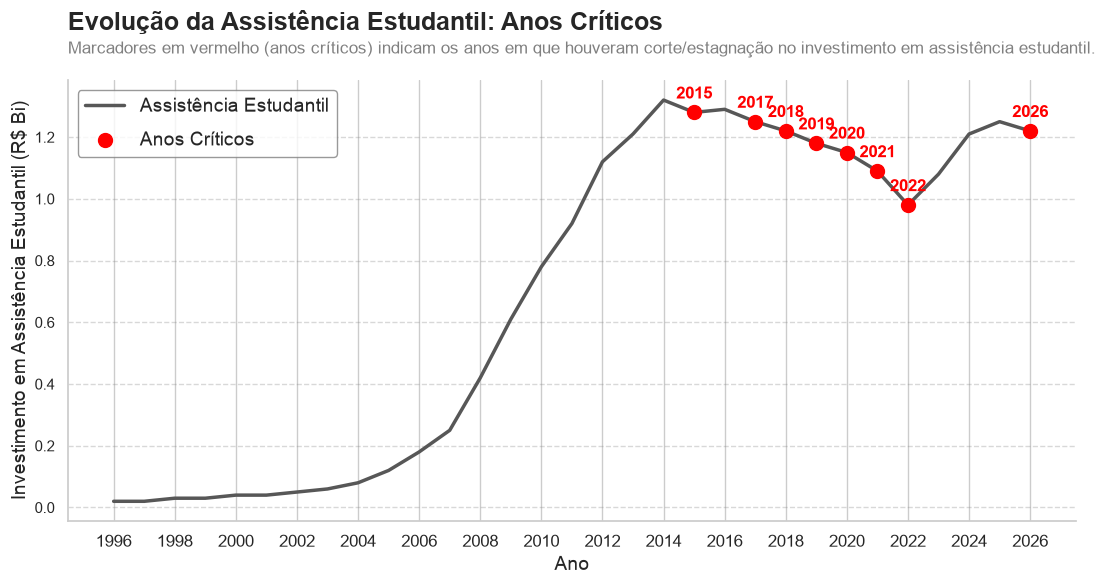

In [224]:
fig, ax = plt.subplots(figsize=(12, 6))

plt.plot(
    df['ano'],
    df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='#575757',
    linewidth=2.5,
    label='Assistência Estudantil',
)

criticos_df = df[df['ano'].isin(anos_criticos)]
plt.scatter(
    criticos_df['ano'],
    criticos_df['investimento_assistencia_estudantil_bilhoes_brl'],
    color='red',
    s=100,
    zorder=5,
    label='Anos Críticos',
)

for ano in anos_criticos:
  y_val = df.loc[df['ano'] == ano, 'investimento_assistencia_estudantil_bilhoes_brl'].values[0]
  plt.annotate(
      f'{ano}',
      (ano, y_val),
      textcoords='offset points',
      xytext=(0, 10),
      ha='center',
      fontweight='bold',
      color='red',
  )

plt.xlabel('Ano', fontsize=14)
plt.ylabel('Investimento em Assistência Estudantil (R$ Bi)', fontsize=14)

anos_xticks = range(df['ano'].min(), df['ano'].max() + 1, 2)
plt.xticks(anos_xticks, fontsize=12)

# Deixa as linhas horizontais de referencia mais discretas
ax.yaxis.grid(True, linestyle='--', alpha=0.3, color='gray')
ax.set_axisbelow(True)

# Remove as bordas desnecessarias do grafico
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.legend( 
    loc='upper left',
    fontsize=14,
    frameon=True,
    edgecolor='gray',
    labelspacing=0.8,
)

plt.title(
    'Evolução da Assistência Estudantil: Anos Críticos', 
    fontsize=18,
    loc='left',
    fontweight='bold',
    pad=36
)
# Subtítulo
ax.text(
    x=0, y=1.06,
    s='Marcadores em vermelho (anos críticos) indicam os anos em que houveram corte/estagnação no investimento em assistência estudantil.',
    transform=ax.transAxes,
    fontsize=12,
    color='gray',
)

plt.tight_layout()
plt.show()

A análise do gráfico revela que no período de 1996 a 2014 houve um crescimento exponencial no Investimento Assistência Estudantil. Contudo, quase todos os anos subsequentes apresentaram queda até o ano de 2022. 

Depois disso, a partir de 2023, o investimento voltou a crescer, com exceção do ano de 2026, onde o investimento caiu novamente. Isso pode ser explicado porque o ano de 2026 ainda não terminou, logo o investimento deve aumentar até o final do ano.

Foi escolhido o gráfico de linhas com marcações em cor vermelha nos anos onde houve uma queda no investimento assistência estudantil, sem levar em conta se o número de vagas cresceu ou não. Essa escolha se deve ao gráfico de linhas ser ótimo para analisar séries temporais (neste caso, o Investimento Assistência Estudantil) com as marcações em vermelho permitindo visualizar facilmente os anos em que houve esse comportamento entre o investimento e número de vagas.

## Etapa 5 - Métricas Customizadas via *apply* e Paletas de Cores

In [ ]:
def classificar_expansao(variacao):
    if variacao < 0:
        return 'Retração Orçamentária'
    elif variacao <= 5.0: # crescimento de até 5%
        return 'Média Expansão'
    else:
        return 'Alta Expansão'

In [ ]:
df['variacao_investimento_pct'] = df['investimento_total_ifes_bilhoes_brl'].pct_change() * 100

df['categoria_expansao'] = df['variacao_investimento_pct'].apply(classificar_expansao)

# Define categorias para que a paleta do seaborn seja aplicada corretamente
df['categoria_expansao'] = pd.Categorical(
    df['categoria_expansao'],
    categories=['Retração Orçamentária', 'Média Expansão', 'Alta Expansão'],
    ordered=True
)

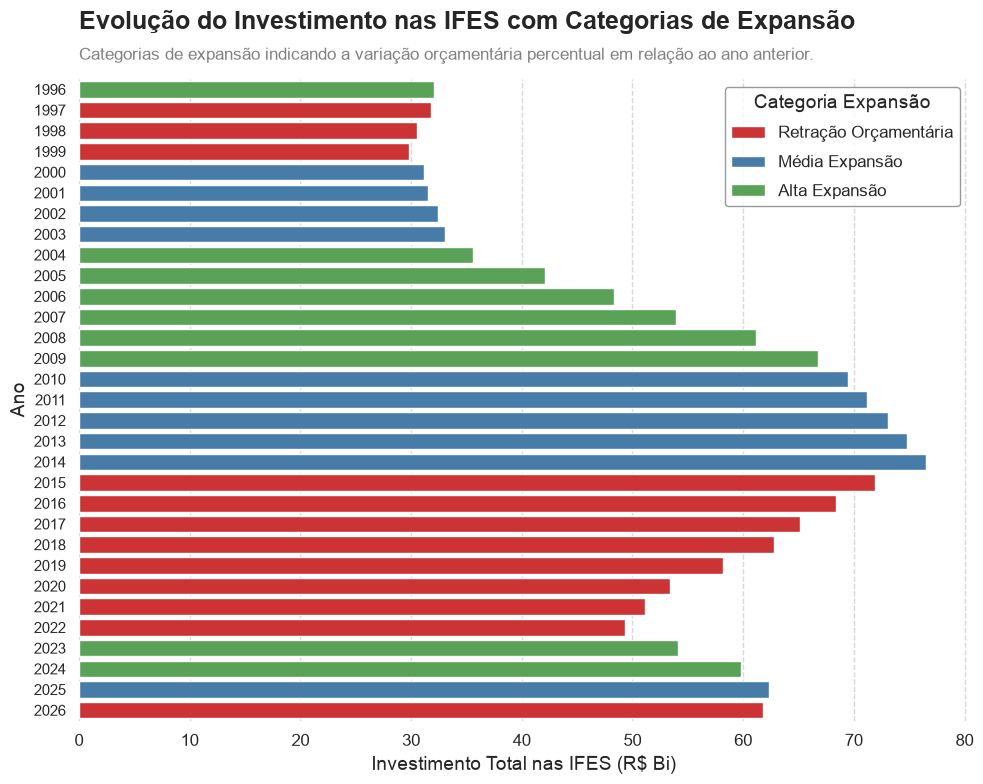

In [228]:
fig, ax = plt.subplots(figsize=(10, 8))

sns.barplot(
    data=df,
    y='ano',
    x='investimento_total_ifes_bilhoes_brl',
    hue='categoria_expansao',
    palette='Set1',
    dodge=False,
    orient='h', # barras horizontais
    ax=ax,
)

# Remove as bordas desnecessarias do grafico
ax.spines['top'].set_visible(False)
ax.spines['bottom'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.xaxis.grid(True, linestyle='--', alpha=0.3, color='gray')

plt.xlabel('Investimento Total nas IFES (R$ Bi)', fontsize=14)
plt.ylabel('Ano', fontsize=14)

plt.xticks(fontsize=12)

ax.set_title(
    'Evolução do Investimento nas IFES com Categorias de Expansão',
    fontsize=18,
    fontweight='bold',
    loc='left',
    pad=36
)
# Subtítulo
ax.text(
    x=0, y=1.03,
    s='Categorias de expansão indicando a variação orçamentária percentual em relação ao ano anterior.',
    transform=ax.transAxes,
    fontsize=12,
    color='gray',
)

ax.legend(
    title="Categoria Expansão",
    title_fontsize=14,
    fontsize=12,
    loc='upper right',
    frameon=True,
    edgecolor='gray',
    labelspacing=0.8,
)

fig.tight_layout()
plt.show()

A paleta escolhida é fundamental para auxiliar o leitor a associar a cor ao fenômeno de expansão do investimento nas IFES. 

A cor vermelha é universalmente vinculada à déficit, e ao atribuí-la à retração, o leitor identifica instantaneamente os anos de corte orçamentário.

A cor azul funciona como estado de transição, representando um crescimento pequeno (reposição inflacionária).

Por fim, a cor verde é altamente ligada à superávit, transmitindo a informação de que ocorreu um aumento no investimento nas IFES.